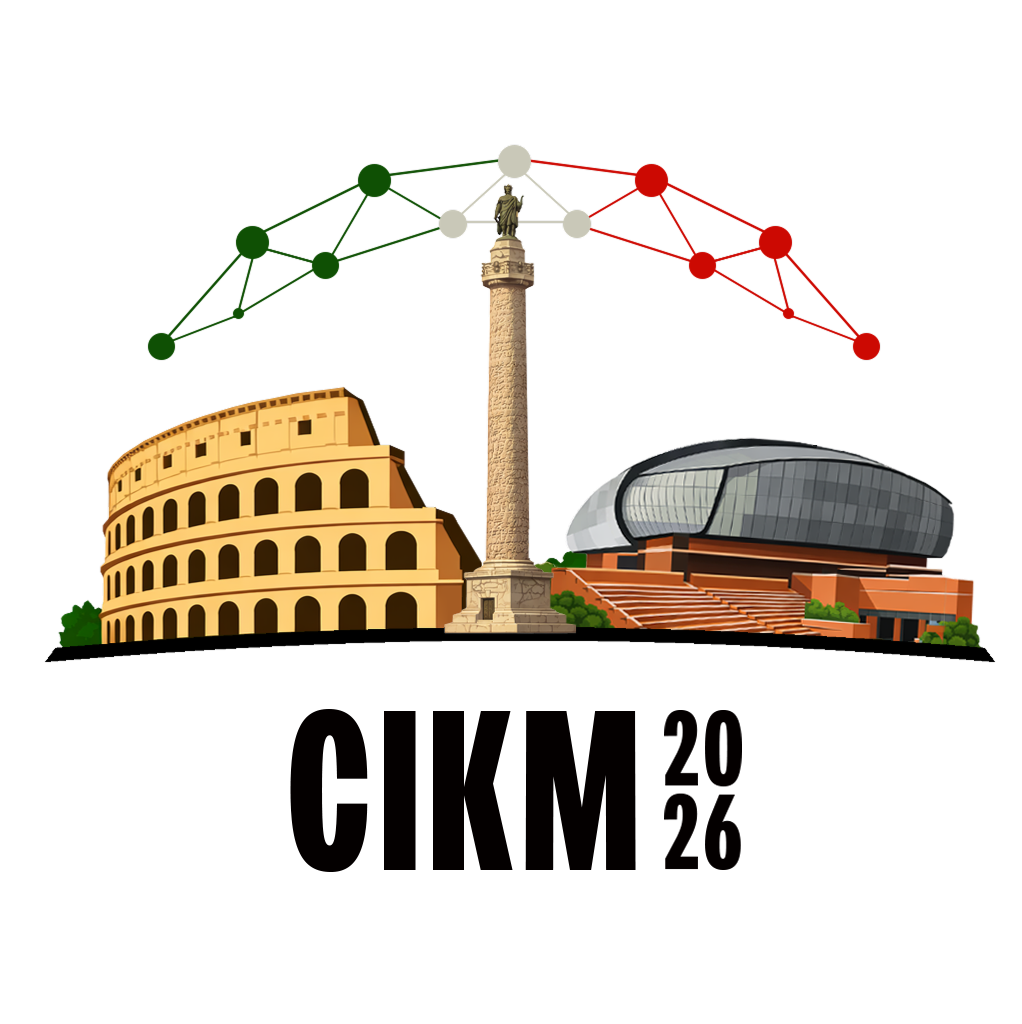

# M6: Report results and check updates

Beyond Benchmarks: Robustness for Real-World Information Systems

Bum Jun Kim, The University of Tokyo, CIKM 2026

7 November 2026 · [San Pietro in Vincoli Campus, Sapienza University of Rome](https://cikm2026.diag.uniroma1.it/venues/) · Rome, Italy

Learning objective: Decide whether to use a repair, detect quality losses after an update, and confirm that rollback restores search quality.

Run this notebook on its own with Restart Kernel → Run All. See the [README](README.md) for setup and the [appendix](#m6-reference) for evaluation details.


<a id="m6-industry-scenario"></a>
## Should we add query repair?

A scientific literature assistant uses dense search without repair. The team wants to add one of M4's repairs.

First test the repair. It must help typo queries and avoid unacceptable losses on correctly written queries. Go means use the repair in this simulation. Hold means keep original search.

Save scores for the chosen system. After an update, repeat the same check on SciFact queries with known relevance labels. Keep the papers and encoder fixed. Reranking is off.

Everything runs offline; no system is deployed. The later bug affects whichever system the decision kept in use, including original search after Hold.


In [1]:
# Load the cached SciFact data and choose the repair to evaluate.
from pathlib import Path
import sys
ROOT = next(p / "resources" for p in [Path.cwd(), *Path.cwd().parents] if (p / "resources" / "tutorial_utils").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
%matplotlib inline
from tutorial_utils.presentation import install_plain_display
install_plain_display()
from tutorial_utils import load_tutorial_context
from tutorial_utils import reporting

MODE = "cached"
ctx = load_tutorial_context(mode=MODE, seed=42)
# The adapter uses fixed one-edit training and validation; severity sets test edits.
intervention = "repair_adapter"
severity = 1
print(f"SciFact: {len(ctx.corpus):,} documents, {len(ctx.test_ids)} test queries, cached results")

SciFact: 5,183 documents, 300 test queries, cached results


<a id="m6-settings"></a>
## Experiment Settings

Set two allowed score losses:

- `clean_drop_tolerance`: allowed mean original-query nDCG@10 loss when approving a repair. Check the lower end of the gain's 95% interval against this limit.
- `quality_tolerance`: allowed mean nDCG@10 or Recall@10 loss from the saved monitoring scores.

Monitoring also checks severe losses on individual queries. The rules are defined below.

After changing a value, select the code cell below and use Run All Below. Tolerances change pass/fail decisions; they do not change the measured scores. Set them before reading the results.


In [2]:
# Set the allowed score drops for repair approval and monitoring.
clean_drop_tolerance = 0.01
quality_tolerance = 0.01

## Does the repair improve search?

Use M4's paired comparison: compare the repair with original search on the same input, original with original and typo with typo. Higher nDCG@10 and Recall@10 are better.

M4 uses the selected `severity` for adapter validation. Here adapter training and validation stay at one edit; `severity` changes only the test inputs. Both modules use the same adapter at the default `severity=1`. Changing M6's test severity keeps that adapter fixed.

Gain = repair score − original-search score. Positive means improvement; negative means harm.

The decision also uses 95% intervals. These show how the mean gain may vary across samples of queries. A positive mean alone does not pass the benefit check.


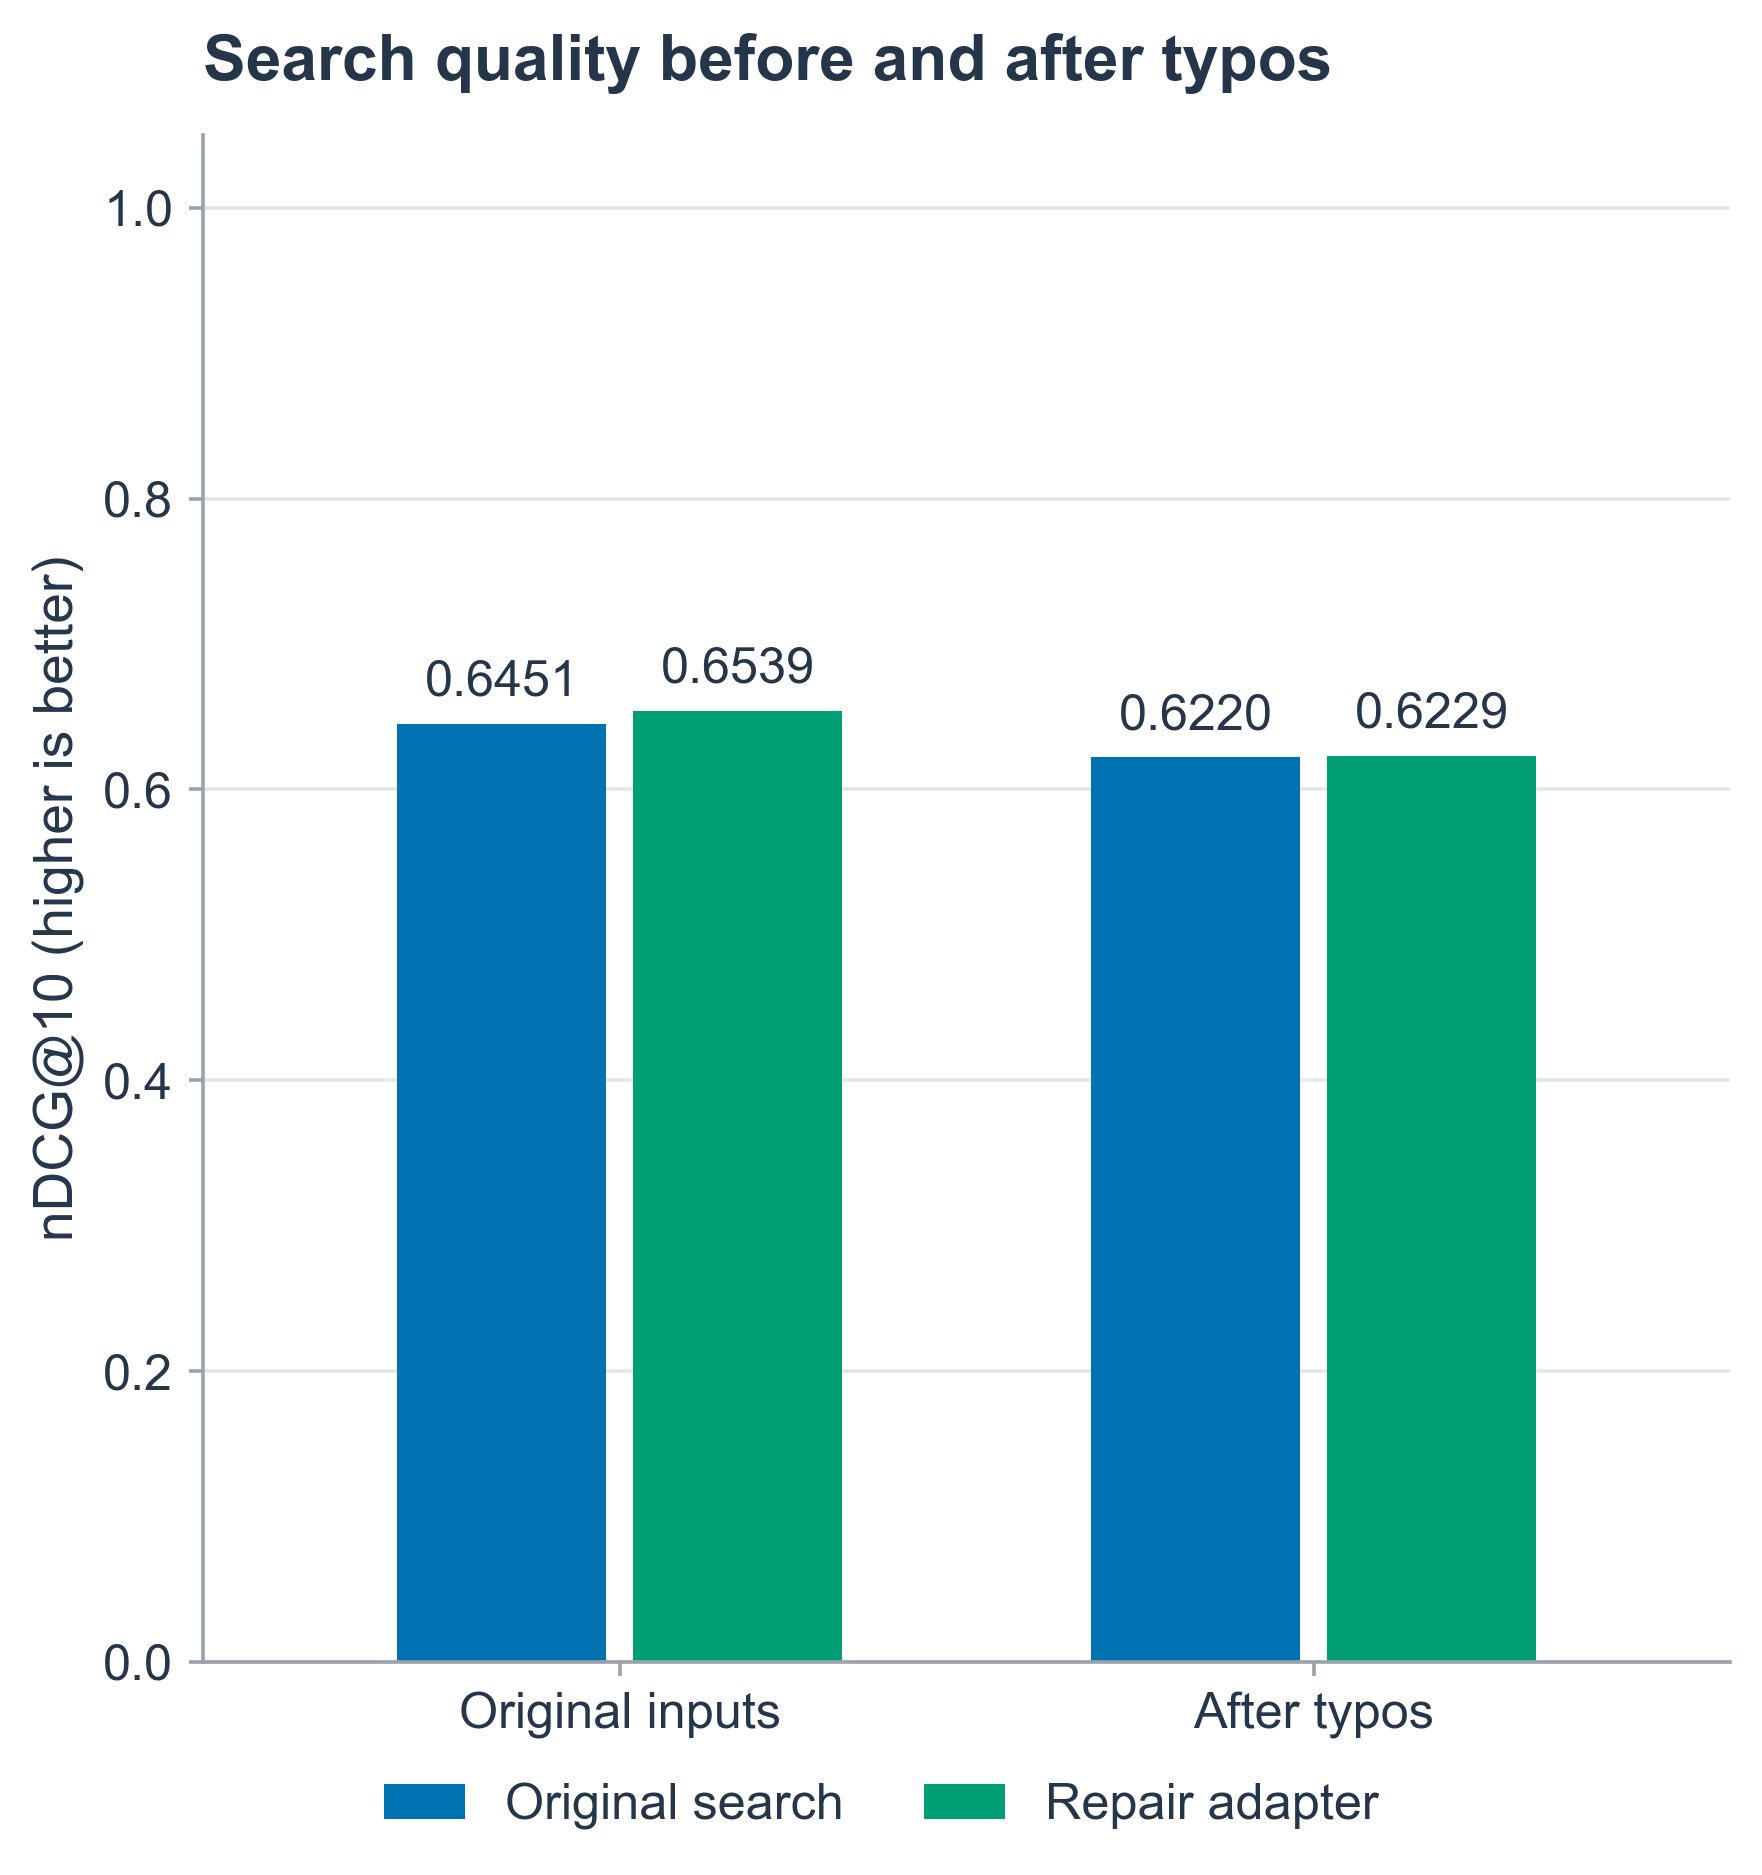

Method,nDCG@10 original,nDCG@10 after typos,Recall@10 original,Recall@10 after typos
Original search,0.6451,0.6220,0.7833,0.7699
Repair adapter (candidate),0.6539,0.6229,0.7967,0.7617


In [3]:
# Build the robustness report and compare repair scores on original and typo queries.
report = reporting.build_robustness_report(
    ctx, intervention=intervention, severity=severity,
    clean_drop_tolerance=clean_drop_tolerance,
    quality_tolerance=quality_tolerance)
reporting.show_evaluation(report)

## Decide: Go or Hold

Go requires all three checks to pass:

- Help typo queries: the lower end of the mean typo-gain 95% interval is above 0.
- Limit harm to original queries: the lower end of the mean original-query gain interval is at least −`clean_drop_tolerance`.
- Avoid severe losses on original queries: no query loses all the relevant papers it had in the top ten, or loses at least 0.5 nDCG@10.

Any failed check gives Hold. Keep original search, improve the repair, and test it again.

Choose the rules before evaluation. Relaxing them after seeing test scores can turn Hold into Go without improving search. That also uses the test set to tune the decision.

Go means the repair passed these offline checks. Evaluate real user queries before using it in a live system.


In [4]:
# Show whether the repair passes each check for a Go decision.
reporting.show_decision(report)

Method,Typo gain [95% CI],Original-query gain [95% CI],Severe original-query losses,Decision
Input normalization,"fail: +0.0000 [+0.0000, +0.0000]","pass: +0.0000 [+0.0000, +0.0000]",pass: 0,Hold
Vocabulary correction,"pass: +0.0217 [+0.0054, +0.0381]","pass: -0.0019 [-0.0057, +0.0001]",fail: 1,Hold
Repair adapter (candidate),"fail: +0.0010 [-0.0119, +0.0147]","pass: +0.0088 [-0.0020, +0.0210]",fail: 4,Hold


Decision: Hold. Repair adapter: its typo-gain interval is +0.0010 [-0.0119, +0.0147]. It includes zero, so we cannot conclude that the repair helps. Also, it causes severe losses on 4 original queries, for example the claim “Tirasemtiv has no effect on fast-twitch muscle.” (nDCG@10 1.0000 → 0.3010). Keep original search in use. Improve the repair and test it again before use.

Decision: Hold. Vocabulary correction: it improves typo queries (+0.0217 [+0.0054, +0.0381]). However, it causes a severe loss on 1 original query: the claim “The risk of male prisoners harming themselves is ten times that of female prisoners.” (nDCG@10 1.0000 → 0.4307, where correction replaces harming → warming). Keep original search in use. Improve the repair and test it again before use.

## Monitor: Repeat the same quality check

Save the chosen system's scores on the original queries and their fixed typo versions. After an update, run those same inputs and compare the scores.

Trigger an alert if either happens:

- Mean nDCG@10 or Recall@10 falls by more than `quality_tolerance` on original or typo inputs.
- Any query loses every relevant paper it had in the top ten, or loses at least 0.5 nDCG@10.

Compare each result with the saved result for the same input. An unchanged system should match the saved scores and add no severe failures.


In [5]:
# Compare current search quality with the saved reference scores.
reporting.show_monitoring(report)

Quality measure,Saved reference,Current run,Current − reference
"nDCG@10, original queries",0.6451,0.6451,+0.0000
"nDCG@10, typo queries",0.6220,0.6220,+0.0000
"Recall@10, original queries",0.7833,0.7833,+0.0000
"Recall@10, typo queries",0.7699,0.7699,+0.0000
Severe failures,0,0,–


Monitored system: original search, the system kept in use. Repair adapter is on hold, so it is not deployed or monitored.

## Alert: Simulate a bug

The bug gives 10% of typo queries the results for a different query. It always affects the same queries. Original queries keep their results.

Only the result lists in memory change. The papers and models stay fixed. Any loss therefore comes from the query-handling bug.


In [6]:
# Show whether the quality checks detect the simulated faulty update.
reporting.show_alerts(report)

Check,Triggers when,Unchanged run,Simulated regression
Average quality loss,average nDCG@10 or Recall@10 falls more than 0.01 below the saved score,"+0.0000, pass","-0.0617 (Recall@10, typo queries), fail"
Severe query loss,any query loses all relevant papers from the top 10 or falls 0.5 or more in nDCG@10,"0 queries, pass","19 queries, fail"
Quality alert,either check fails,No alert,Alert


## Recover: Roll back and check again

The Search Team inspects a failed query, removes the faulty update, and repeats the same test.

Confirm recovery when scores match the saved scores, no new severe failures remain, and the alert clears. Check these results after rollback.


In [7]:
# Inspect a failed query and verify recovery after rollback.
reporting.show_response(report)

Changed results: 30 typo queries and 0 original queries.

Mean typo-score changes: nDCG@10 -0.0524; Recall@10 -0.0617. Severe failures: 19.

Check: Original queries kept their top ten. Only typo results changed. Check the query-handling update first. Owner: Search Team.

Example: Query (after typos): Taxation of sugar-sweetened beverages had no effect on the ijcidence rate of type II diabetes in India. Saved result: relevant paper at rank 1, nDCG@10 1.0000. Current result: no relevant paper in the top 20, nDCG@10 0.0000. First paper now: TEAD mediates YAP-dependent gene induction and growth control.

Roll back: Roll back the faulty query-handling update to the system that produced the saved reference. Any new fix must pass the release checks before use.

Verify: rerun the same test queries and fixed typos after rollback.

Quality measure,Saved reference,Simulated regression,After rollback
"nDCG@10, original queries",0.6451,0.6451,0.6451
"nDCG@10, typo queries",0.6220,0.5696,0.6220
"Recall@10, original queries",0.7833,0.7833,0.7833
"Recall@10, typo queries",0.7699,0.7082,0.7699
Severe failures,0,19,0
Quality alert,No alert,Alert,No alert


## Save the report

The report records the settings, scores and intervals, decisions and reasons, monitoring results, failure examples, rollback checks, and details needed to repeat the run.

It saves `resources/outputs/robustness_report.md` and `resources/outputs/robustness_report.json`. Download links appear below.


In [8]:
# Save the report as Markdown and JSON and display download links.
saved = reporting.save_report(report)
reporting.show_downloads(saved)

## Lesson Summary

Approve a repair only after checking the mean gain, its uncertainty, and individual failures. Monitor the system kept in use. After rollback, rerun the test to confirm recovery.

Changing a tolerance changes the decision, not search quality. Optional formulas and simulation details follow.


<a id="m6-reference"></a>
## Appendix: Score differences and the decision rule

[M1's appendix](M1_Observe_Failures.ipynb#m1-ndcg-appendix) defines the metrics. $R_I(q,s)$ is method $I$'s nDCG@10 for query $q$ with up to $s$ edits. $R_{\mathrm{base}}(q,s)$ is original search's score on that same input.

Use matching query IDs to calculate each difference, then average. Higher is better.

| Quantity | Calculation | Comparison |
| --- | --- | --- |
| Effect of typos within a method | $D_I=\operatorname{mean}_q[R_I(q,s)-R_I(q,0)]$ | Same method, different input |
| Repair gain after typos | $G_s=\operatorname{mean}_q[R_I(q,s)-R_{\mathrm{base}}(q,s)]$ | Same typo input, different method |
| Repair gain on original input | $G_0=\operatorname{mean}_q[R_I(q,0)-R_{\mathrm{base}}(q,0)]$ | Same original input, different method |

Interpretation: Approval uses the last two rows, which compare the repair with original search on the same input, while the first row only measures typo damage within one method.

Each 95% interval uses 500 bootstrap samples. Draw query IDs with replacement and keep each query's repair and baseline scores together.

Let $L(\cdot)$ be the lower end of an interval and $\epsilon=$ `clean_drop_tolerance`:

$$\mathrm{Go}=\mathbf{1}\left[L(G_s)>0\ \wedge\ L(G_0)\ge-\epsilon\ \wedge\ B_I=0\right].$$

This gives Go only when all three checks pass. $B_I$ counts original queries with a severe loss: all previously retrieved top-ten evidence disappears, or nDCG@10 falls by at least 0.5.

Monitoring uses the same severe-loss rule, comparing with the saved scores for the same input. Differences smaller than $10^{-12}$ count as zero. An unchanged run triggers no alert, even at tolerance 0.


<a id="m6-ranking-reference"></a>
## Appendix: Compare ranking changes

[M1's finite RBO@10](M1_Observe_Failures.ipynb#m1-rbo) compares original and typo top-ten lists. Higher means more agreement. Relevance still needs a separate check.

Rank drift = 1 − mean RBO. Lower means more agreement between original and typo results.

Additional drift = current rank drift − saved rank drift.

Rank drift compares original and typo lists within a run. Additional drift compares those amounts between runs. Neither directly compares saved and current document lists. Neither controls Go/Hold or alerts.

An unchanged system can have nonzero rank drift because typos change its results. Its additional drift is zero because it matches the saved run.


In [9]:
# Show ranking changes between original and typo queries.
reporting.show_ranking_reference(report)

Run,Rank drift (1 − RBO@10),Additional drift
Saved reference,0.2299,+0.0000
Unchanged run,0.2299,+0.0000
Simulated regression,0.2998,+0.0699
After rollback,0.2299,+0.0000


## Appendix: Repeat the simulation

Select a fixed 10% of misspelled test queries and keep them in test order. Give each one the next selected query's typo results. The last gets the first's results. Original queries stay unchanged. Rollback reruns the saved system. Nothing is deployed.

To try another setting, change these values in the setup cell and run it and all later cells:

- `intervention`: `none`, `input_normalization`, `vocab_spell_correction`, or `repair_adapter`.
- `severity`: 0–3 for test inputs only. Adapter training and validation stay at one edit. Zero adds no test typos and skips the bug.

[M4's reference](M4_Improve_Robustness.ipynb#m4-reference) explains adapter training and validation.

With the default repair and severity:

- `clean_drop_tolerance=0.05` still gives Hold. It allows a larger original-query loss, but does not establish a typo benefit or remove severe losses.
- `quality_tolerance=0.10` lets the average-loss check pass. The 19 severe failures still trigger an alert.

Set tolerances before reading test results. The JSON report saves every query's scores, model revisions, data checksums, and ranking diagnostics.


### Sources to read

- Mitchell et al. (FAT* 2019), [Model Cards for Model Reporting](https://doi.org/10.1145/3287560.3287596): recording evaluation results and intended use.
- Sculley et al. (NIPS 2015), [Hidden Technical Debt in Machine Learning Systems](https://proceedings.neurips.cc/paper_files/paper/2015/hash/86df7dcfd896fcaf2674f757a2463eba-Abstract.html): maintaining machine-learning systems after deployment.
